# Más allá: la UF como moneda propia y una prueba que detecta un supuesto de comportamiento cambiado ante un incumplimiento de límite

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los cuadernos 01 a 07 de este tema
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar las dos afirmaciones de este tema, BS-7 (la UF como moneda propia en IRRBB) y BS-8 (una prueba que marca un supuesto de comportamiento cambiado ante un incumplimiento de límite), la evidencia versionada de cada una, la práctica que cada una supera y el límite de cada afirmación;
- mostrar, con el motor, qué perdería un tratamiento de la UF como una sola moneda frente al Anexo 1 (tamaños, piso, compensación y cargo);
- correr la prueba de incumplimiento sobre historiales controlados y sobre los parámetros versionados, y decir qué discrimina y qué no;
- decir qué hace un validador con un resultado rojo de esta prueba;
- comparar cada recálculo con el valor versionado, nombrando la versión del motor que lo calculó.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import eve_nii, shocks, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Datos

Dos casos alimentan las dos afirmaciones.

- **BS-7** lee el caso C15, el Banco Andino **sintético** sobre un balance en pesos y UF al 2026-09-03, en cuatro de sus seis variantes: `short-uf`, `long-uf`, `offset-on-off` y `floors-active`. Los agregados del balance están calibrados a las cifras del sistema de la CMF de agosto de 2026 (https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf, estadísticas públicas, clase de licencia `mirror-allowed`); las curvas son los rendimientos reales del Banco Central de Chile (cuadro F022 de la BDE, `mirror-allowed`). El dinero está en millones de CLP.
- **BS-8** lee el caso C14, el banco que quebró en marzo de 2023, en las fechas de valoración 2021-Q4, 2022-Q2 y 2022-Q4: los reportes de condición de la FDIC (https://api.fdic.gov/banks/financials) y la curva a la par del Tesoro de EE. UU. (https://home.treasury.gov/resource-center/data-chart-center/interest-rates), fuentes de dominio público de la clase de licencia `mirror-allowed`. El banco es **real en agregado y sintético en comportamiento**: la proporción y el plazo de los depósitos estables los declara Contraste, y el plazo de la cartera replicante se ajusta con el historial de reportes. El dinero está en miles de USD.

Un delta EVE o delta NII positivo es una pérdida en ambos.

- **Archivos que se leen:** `data/derived/C15/short-uf.json`, `long-uf.json`, `offset-on-off.json` y `floors-active.json` (`outputs.legs`, `curves`, `eve`, `nii`, `floors`, `offset_rule`, `indexation_charge`, `thresholds`), `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` y `vd-2022-q4.json` (`outputs.nmd_segments`, `scenarios`; `tests`) y `data/derived/C14/models-svb-2021-2022.json` (`fit.nmd_models`, `nmd_parameter_changes`).

La celda siguiente carga los archivos e imprime la versión del motor que los calculó.

In [2]:
# Cargar las cuatro variantes de C15, las tres fechas de valoración de C14 y el documento de modelos de C14 (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
variants = {v: json.loads((ROOT / "data" / "derived" / "C15" / f"{v}.json").read_text(encoding="utf-8")) for v in ("short-uf", "long-uf", "offset-on-off", "floors-active")}
docs = {q: json.loads((ROOT / "data" / "derived" / "C14" / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in ("2021-Q4", "2022-Q2", "2022-Q4")}
fit = json.loads((ROOT / "data" / "derived" / "C14" / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
MID = slotting.bucket_grid().midpoints
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
# Nombres en este idioma de los valores propios del documento (los identificadores del archivo quedan como están)
NAME = {"parallel-up": "paralelo al alza", "parallel-down": "paralelo a la baja", "steepener": "empinamiento",
        "flattener": "aplanamiento", "short-up": "corto al alza", "short-down": "corto a la baja", True: "sí", False: "no"}
for v, d in variants.items():
    print(f"C15 {v:14s} | calculado por riskvalidation {d['provenance']['riskvalidation_version']} | instalado {rv.__version__}")
for q, d in docs.items():
    print(f"C14 {q:14s} {d['outputs']['valuation_date']} | calculado por riskvalidation {d['provenance']['riskvalidation_version']} | instalado {rv.__version__}")

C15 short-uf       | calculado por riskvalidation 0.9.0 | instalado 0.9.0
C15 long-uf        | calculado por riskvalidation 0.9.0 | instalado 0.9.0
C15 offset-on-off  | calculado por riskvalidation 0.9.0 | instalado 0.9.0
C15 floors-active  | calculado por riskvalidation 0.9.0 | instalado 0.9.0
C14 2021-Q4        2021-12-31 | calculado por riskvalidation 0.9.0 | instalado 0.9.0
C14 2022-Q2        2022-06-30 | calculado por riskvalidation 0.9.0 | instalado 0.9.0
C14 2022-Q4        2022-12-31 | calculado por riskvalidation 0.9.0 | instalado 0.9.0


## Método

El cuaderno enuncia cada afirmación, muestra la evidencia de los archivos versionados con el motor, y muestra un control o un contrafactual que hace comprobable la afirmación: para BS-7 el costo de no tratar la UF como una moneda, para BS-8 historiales donde la prueba debe dar verde y donde debe dar rojo. Cada afirmación termina con su límite. Las afirmaciones y su evidencia están enunciadas en la sección `## Beyond the state of the art` del SDD; el cuaderno no afirma más de lo que afirma el SDD.

- **BS-7.** El riesgo de reajustabilidad del Anexo 1 de la RAN 21-13 como una moneda separada (la UR) con sus propios choques, piso, el cargo por reajustabilidad (2,5 por ciento de la posición neta en UF en valor absoluto) y la compensación de 50 por ciento del delta en pesos contra el delta UR. Evidencia: `data/derived/C15/long-uf.json`, `floors-active.json`, `offset-on-off.json`.
- **BS-8.** La prueba `irrbb.behavioural_change_at_breach`, que convierte un hallazgo de la revisión de la Reserva Federal sobre el banco quebrado en una prueba de validación. Evidencia: las filas versionadas de `data/derived/C14/vd-2022-q2.json`.

## Estado del arte

**Para BS-7.** El estándar de Basilea tiene 21 monedas en su tabla de choques y una regla para agregarlas; no tiene una unidad como la UF, una unidad de cuenta reajustable cuyo valor en moneda local sigue a la inflación, y ninguna moneda de la jurisdicción local que falte en la tabla recibe un tamaño (SRP31.90, Tabla 2; BCBS d578, https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf). El Anexo 1 del capítulo 21-13 del regulador chileno (https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf) llena esa brecha con la UR. La investigación encontró el enfoque chileno descrito como "un diferenciador genuino" (dossier 03, F.2) y no encontró una implementación pública del Anexo; es un hallazgo de la búsqueda del dossier y sigue **NO VERIFICADO** más allá de ella. La afirmación es regional, no global.

**Para BS-8.** La revisión de la Reserva Federal sobre Silicon Valley Bank enuncia la práctica como un hallazgo: el banco "había incumplido sus límites de riesgo de tasa de largo plazo de forma intermitente desde 2017" y "en abril de 2022 ... hizo supuestos de modelación contraintuitivos sobre la duración de los depósitos para enfrentar el incumplimiento del límite en vez de gestionar el riesgo real" (https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf; dossier 05, D.7). La investigación propone la prueba ("una prueba de validación de Contraste debería entonces marcar todo cambio en los parámetros de comportamiento de los depósitos que coincida con un incumplimiento de límite") y no cita ninguna herramienta que la implemente.

La primera celda de abajo muestra el primer hecho de BS-7 con el motor: la tabla de Basilea no tiene entrada para el peso ni para la UF, y el motor rechaza un tamaño para ellos en vez de inventarlo.

In [3]:
# La tabla de Basilea no tiene entrada para el peso ni para la UF: el motor rechaza un tamaño; la tabla chilena tiene ambos
for calibration in ("2016", "2024"):
    table = shocks.shock_table(calibration)
    print(calibration, "| monedas:", len(table), "| CLP:", NAME["CLP" in table], "| CLF:", NAME["CLF" in table])
for currency in ("CLP", "CLF"):
    try:
        shocks.shock_size(currency, "2024")
    except ValueError as error:
        print(currency, "rechazado (mensaje del motor, en inglés):", str(error)[:80], "...")
for currency in ("CLP", "CLF"):
    z = shocks.shock_size(currency, "cmf-annex1")
    print(f"{currency} cmf-annex1: {z.parallel_bp:.0f}/{z.short_bp:.0f}/{z.long_bp:.0f} pb | origen {z.origin}")

2016 | monedas: 21 | CLP: no | CLF: no
2024 | monedas: 21 | CLP: no | CLF: no
CLP rechazado (mensaje del motor, en inglés): CLP has no shock size under 2024: supply the size with its label and method (a s ...
CLF rechazado (mensaje del motor, en inglés): CLF has no shock size under 2024: supply the size with its label and method (a s ...
CLP cmf-annex1: 300/400/200 pb | origen cmf-annex1
CLF cmf-annex1: 200/250/150 pb | origen cmf-annex1


## Más allá del estado del arte

### BS-7: la UF como moneda propia

**Lo que agrega la afirmación.** El Anexo 1 del capítulo 21-13 trata el riesgo de reajustabilidad como una moneda separada con sus propios choques, su propio piso, el cargo por reajustabilidad y la compensación de 50 por ciento; el motor lo implementa, y las variantes versionadas de C15 se recalculan desde él. La primera celda muestra la separación en los documentos versionados: los tamaños y el piso de cada moneda y la curva en que se descuenta cada una. La segunda muestra por qué el piso debe ser el propio de la moneda: la curva UR es una curva de tasas reales, de 1,2 a 2,8 por ciento, y un choque a la baja de 200 pb empuja su extremo corto bajo cero, donde el piso del peso de 0 por ciento actuaría en nueve bandas y el piso UR de -2 por ciento en ninguna.

In [4]:
# Los tamaños, el piso y la curva de cada moneda en los documentos versionados, y el tamaño del motor para cada una
out = variants["short-uf"]["outputs"]
rates = {"CLP": np.array(out["curves"]["clp"]["zero_rates_at_midpoints"]), "UR": np.array(out["curves"]["ur"]["zero_rates_at_midpoints"])}
floors = {"CLP": out["floors"]["other_floor"], "UR": out["floors"]["ur_floor"]}
print(f"{'':4s} {'tamaños EVE (par/corto/largo)':>40s} {'tamaño NII':>14s} {'piso':>8s} {'tasa, banda 1':>16s} {'tasa, banda 19':>17s}")
for committed in out["eve_shock_sizes"]:
    leg = "CLP" if committed["currency"] == "CLP" else "UR"
    nii = next(x["parallel_bp"] for x in out["nii_shock_sizes"] if x["currency"] == committed["currency"])
    z = shocks.shock_size(committed["currency"], "cmf-annex1")
    same = (z.parallel_bp, z.short_bp, z.long_bp) == (committed["parallel_bp"], committed["short_bp"], committed["long_bp"])
    print(f"{leg:4s} {committed['parallel_bp']:.0f}/{committed['short_bp']:.0f}/{committed['long_bp']:.0f}{'':>26s} {nii:14.0f} {floors[leg]:8.2f} {rates[leg][0]:16.5f} {rates[leg][18]:17.5f}  igual al motor {NAME[same]}")

                tamaños EVE (par/corto/largo)     tamaño NII     piso    tasa, banda 1    tasa, banda 19
CLP  300/400/200                                      300     0.00          0.04499           0.05911  igual al motor sí
UR   200/250/150                                      300    -0.02          0.01205           0.02839  igual al motor sí


Ahora el piso. La celda siguiente aplica una caída de 200 pb a la curva UR de la primera variante con el piso del peso y luego con el piso UR, y lista las bandas donde cada piso actúa.

In [5]:
# Aplicar una caída de 200 pb a la curva UR con el piso del peso (0) y con el piso UR (-2 por ciento) y contar las bandas donde el piso actúa
raw = shocks.apply_floor(rates["UR"], np.full(19, -200.0), None)
for label, floor in (("piso del peso (0)", 0.0), ("piso UR (-2 por ciento)", -0.02)):
    bound = [int(k) + 1 for k in np.flatnonzero(~np.isclose(shocks.apply_floor(rates["UR"], np.full(19, -200.0), floor), raw))]
    print(f"{label:34s} bandas donde actúa: {bound}")
print("tasa más baja de la curva UR tras -200 pb, antes del piso:", round(float(raw.min()), 5))

piso del peso (0)                  bandas donde actúa: [1, 2, 3, 4, 5, 6, 7, 8, 9]
piso UR (-2 por ciento)            bandas donde actúa: []
tasa más baja de la curva UR tras -200 pb, antes del piso: -0.00795


**El contrafactual: lo que pierde un tratamiento de una sola moneda.** Sin la UR, un banco pondría sus flujos en UF, convertidos a pesos, con los flujos en pesos, los descontaría todos con la curva en pesos, los sometería a los choques con los tamaños del peso y el piso en cero, y no sumaría ningún cargo: una sola moneda. La celda hace exactamente eso con el motor para las cuatro variantes, usando los flujos netos versionados de cada tramo, y compara las dos medidas y las razones al Tier 1. Es un contrafactual, no un método rival: muestra lo que se pierde cuando la UF no es una moneda propia. La diferencia tiene cuatro partes que actúan juntas, la curva (nominal en vez de real), los tamaños (los del peso para los flujos en UF), la compensación total de los tramos dentro de una sola suma, y el cargo ausente.

In [6]:
# Medidas del Anexo 1 contra un tratamiento de una sola moneda con los mismos flujos: curva en pesos, tamaños del peso, piso en cero, sin cargo
peso = shocks.shock_size("CLP", "cmf-annex1")
compare = {}
print(f"{'':14s} {'ΔEVE Annex':>11s} {'ΔEVE única':>12s} {'ΔNII Annex':>11s} {'ΔNII única':>12s} {'ΔNII cargo':>12s} {'ΔEVE/T1 Anexo, única':>26s} {'ΔNII/T1 Anexo, única':>26s}")
for v, d in variants.items():
    o = d["outputs"]
    uf = o["ur_currency"]["uf_value"]
    base = {}
    for leg in o["legs"]:
        vector = np.zeros(19)
        for item in leg["items"]:
            for row in item["cash_flows"]:
                vector[row["bucket"] - 1] += row["amount"]
        base[leg["leg"]] = vector * (1.0 if leg["leg"] == "CLP" else uf)
    r_peso = np.array(o["curves"]["clp"]["zero_rates_at_midpoints"])
    total = base["CLP"] + base["UR"]
    loss_eve = []
    for row in o["eve"]["rows"]:
        net = np.array(row["clp"]["net_cash_flows"]) + np.array(row["ur"]["net_cash_flows"])
        shocked = shocks.apply_floor(r_peso, shocks.shock_curve(row["shock"], peso.parallel_bp, peso.short_bp, peso.long_bp, MID), 0.0)
        loss_eve.append(eve_nii.delta_eve(total, net, r_peso, shocked, MID))
    loss_nii = [eve_nii.delta_nii(total, r_peso, shocks.apply_floor(r_peso, np.full(19, bp), 0.0), MID) for bp in (300.0, -300.0)]
    single_eve, single_nii = max(0.0, max(loss_eve)), max(0.0, max(loss_nii))
    annex_eve, annex_nii, tier1 = o["eve"]["delta_eve"], o["nii"]["delta_nii"], o["thresholds"]["tier1"]
    compare[v] = (annex_eve / tier1, single_eve / tier1, annex_nii / tier1, single_nii / tier1)
    print(f"{v:14s} {annex_eve:11,.0f} {single_eve:12,.0f} {annex_nii:11,.0f} {single_nii:12,.0f} {o['nii']['indexation_charge']:12,.0f} {annex_eve / tier1:12.4f} {single_eve / tier1:12.4f} {annex_nii / tier1:12.4f} {single_nii / tier1:12.4f}")

                ΔEVE Annex   ΔEVE única  ΔNII Annex   ΔNII única   ΔNII cargo       ΔEVE/T1 Anexo, única       ΔNII/T1 Anexo, única
short-uf            79,643       64,213      11,067        1,356        6,182       0.0966       0.0779       0.0134       0.0016
long-uf             93,816       84,710      11,213        1,648        6,182       0.1138       0.1028       0.0136       0.0020
offset-on-off       81,173       59,422      11,016        1,254        6,182       0.0985       0.0721       0.0134       0.0015
floors-active       60,764       49,837       6,606        4,653        1,030       0.0737       0.0605       0.0080       0.0056


**La compensación y el cargo.** La regla de compensación da la mitad del crédito al tramo con ganancia cuando los dos deltas tienen signos opuestos. La variante `offset-on-off` guarda el par con y sin la compensación, y las mismas funciones del motor dan las medidas del Anexo de ambas formas para las cuatro variantes. El cargo se suma una vez al delta NII sea cual sea la compensación. La celda siguiente imprime ambas medidas con y sin la compensación, la proporción del delta NII que es el cargo, y la mayor cercanía de alguna tasa posterior al choque a su piso.

In [7]:
# Las medidas del Anexo con y sin compensación, el cargo como proporción del delta NII y la mayor cercanía a un piso
print(f"{'':14s} {'ΔEVE comp.':>14s} {'ΔEVE sin comp.':>16s} {'ΔNII comp.':>14s} {'ΔNII sin comp.':>16s} {'cargo/ΔNII':>14s} {'piso más cercano (pb)':>22s}")
for v, d in variants.items():
    o = d["outputs"]
    d_clp, d_ur = (np.array([r[leg]["delta_eve"] for r in o["eve"]["rows"]]) for leg in ("clp", "ur"))
    n_clp, n_ur = (np.array([r[leg]["delta_nii"] for r in o["nii"]["rows"]]) for leg in ("clp", "ur"))
    eve_on, eve_off = (eve_nii.annex1_delta_eve(d_clp, d_ur, flag) for flag in (True, False))
    nii_on, nii_off = (eve_nii.annex1_delta_nii(n_clp, n_ur, o["indexation_charge"]["pn_ur"], flag) for flag in (True, False))
    closest = min(x["distance_bp"] for x in o["floors"]["distances"])
    print(f"{v:14s} {eve_on.delta_eve:14,.0f} {eve_off.delta_eve:16,.0f} {nii_on.delta_nii:14,.0f} {nii_off.delta_nii:16,.0f} {nii_on.indexation_charge / nii_on.delta_nii:14.4f} {closest:22.2f}")

                   ΔEVE comp.   ΔEVE sin comp.     ΔNII comp.   ΔNII sin comp.     cargo/ΔNII  piso más cercano (pb)
short-uf               79,643           79,643         11,067           14,597         0.5586                  20.48
long-uf                93,816           94,721         11,213           14,597         0.5513                  20.48
offset-on-off          81,173           94,721         11,016           14,597         0.5612                  20.48
floors-active          60,764           60,764          6,606            7,528         0.1560                  20.48


**El límite de BS-7.** La evidencia muestra que el motor implementa el Anexo 1 como una moneda separada y que las variantes versionadas se recalculan desde él. No muestra que el Anexo se aplique como lo aplica la CMF: no hay una segunda implementación con la cual reconciliar, y la búsqueda del dossier no encontró ninguna (NO VERIFICADO más allá de esa búsqueda). Los pisos están implementados y probados, pero nunca actúan sobre las curvas versionadas, siendo el más cercano uno a 20,48 pb, así que su efecto sobre un número no queda demostrado con estos datos. El banco es sintético. Y la afirmación es regional: el estándar no tiene una unidad como la UF, y solo el Anexo chileno la necesita aquí.

### BS-8: una prueba que marca un supuesto de comportamiento cambiado ante un incumplimiento de límite

**Lo que agrega la afirmación.** `irrbb.behavioural_change_at_breach` recibe la serie de un parámetro de comportamiento, las fechas y una marca de incumplimiento por fecha, y cuenta las fechas en que el parámetro cambió y la marca es verdadera. Es roja con uno o más, verde con ninguno, y `not_evaluated` con menos de dos fechas. La primera celda muestra que la prueba discrimina, sobre cinco historiales construidos cuya respuesta es conocida: un parámetro mantenido fijo durante un incumplimiento, un parámetro que cambia sin incumplimiento, un parámetro cambiado ante un incumplimiento, un parámetro cambiado antes del incumplimiento pero no en él, y una sola fecha. Son números construidos que ejercitan la regla, no datos de ningún banco.

In [8]:
# Cinco historiales construidos con respuesta conocida: fijo bajo un incumplimiento, cambiado sin incumplimiento, cambiado ante un incumplimiento, cambiado antes de él, una fecha
days = np.array(["2021-12-31", "2022-06-30", "2022-12-31"], dtype="datetime64[D]")
cases = [
    ("fijo durante un incumplimiento", [4.0, 4.0, 4.0], [True, True, True], days),
    ("cambiado, sin incumplimiento", [4.0, 4.5, 5.0], [False, False, False], days),
    ("cambiado ante un incumplimiento", [4.0, 4.0, 4.5], [False, False, True], days),
    ("cambiado antes del incumplimiento", [4.0, 4.5, 4.5], [False, False, True], days),
    ("una sola fecha", [4.0], [True], days[:1]),
]
print(f"{'':36s} {'valores':>16s}  {'marcas de incumplimiento':>40s}  luz   fechas marcadas")
for label, values, flags, when in cases:
    run = rv_irrbb.behavioural_change_at_breach(np.array(values), when, np.array(flags, dtype=bool))
    print(f"{label:36s} {str(values):>16s}  {str([NAME[f] for f in flags]):>40s}  {run.light.value:13s} {run.extras.get('flagged_dates', [])}")

                                              valores                  marcas de incumplimiento  luz   fechas marcadas
fijo durante un incumplimiento        [4.0, 4.0, 4.0]                        ['sí', 'sí', 'sí']  green         []
cambiado, sin incumplimiento          [4.0, 4.5, 5.0]                        ['no', 'no', 'no']  green         []
cambiado ante un incumplimiento       [4.0, 4.0, 4.5]                        ['no', 'no', 'sí']  red           ['2022-12-31']
cambiado antes del incumplimiento     [4.0, 4.5, 4.5]                        ['no', 'no', 'sí']  green         []
una sola fecha                                  [4.0]                                    ['sí']  not_evaluated []


**La evidencia en el banco versionado.** El documento de modelos versionado lista, para dos pares consecutivos de fechas, los parámetros de comportamiento de los depósitos mayoristas y si cada uno cambió: la proporción estable y el plazo estable que pide Contraste (declarados, sintéticos) y el plazo promedio ponderado de la cartera replicante ajustada. La celda corre la prueba del motor sobre las tres series de las tres fechas con la marca de incumplimiento de cada fecha tomada de los escenarios versionados, y compara las fechas marcadas con los `nmd_parameter_changes` versionados. Luego corre la misma prueba sobre el plazo promedio con todas las marcas de incumplimiento en falso, como control: el veredicto lo decide la marca, no solo el movimiento.

In [9]:
# Correr la prueba de incumplimiento sobre los tres parámetros de los depósitos mayoristas en las tres fechas, contra los cambios versionados, y un control sin incumplimiento
dates = np.array([d["outputs"]["valuation_date"] for d in docs.values()], dtype="datetime64[D]")
breach = np.array([bool(d["outputs"]["scenarios"][0]["outlier"]["breached"]) for d in docs.values()])
wholesale = [next(s for s in d["outputs"]["nmd_segments"] if s["category"] == "wholesale") for d in docs.values()]
wam = [next(m for m in fit["nmd_models"] if m["valuation_date"] == str(day))["weighted_average_maturity_years"] for day in dates]
series = {
    "proporción estable pedida": [s["requested_core_share"] for s in wholesale],
    "plazo estable pedido (a)": [s["requested_core_maturity_years"] for s in wholesale],
    "plazo promedio ajustado (a)": wam,
}
print("fechas:", [str(x) for x in dates], "| marcas de incumplimiento:", [NAME[bool(b)] for b in breach])
for name, values in series.items():
    run = rv_irrbb.behavioural_change_at_breach(np.array(values), dates, breach)
    print(f"{name:52s} {[round(v, 4) for v in values]} -> luz {run.light.value:5s} marcados {run.extras['flagged_dates']}")
control = rv_irrbb.behavioural_change_at_breach(np.array(wam), dates, np.zeros(3, dtype=bool))
print("control: el mismo plazo ajustado sin incumplimiento -> luz", control.light.value)
flagged_committed = sorted({c["to_date"] for c in fit["nmd_parameter_changes"] if c["flagged"]})
print("fechas marcadas en los cambios versionados:", flagged_committed, "| igual a las del motor sobre el plazo ajustado:", NAME[flagged_committed == run.extras["flagged_dates"]])

fechas: ['2021-12-31', '2022-06-30', '2022-12-31'] | marcas de incumplimiento: ['sí', 'sí', 'sí']
proporción estable pedida                            [0.6, 0.6, 0.6] -> luz green marcados []
plazo estable pedido (a)                             [5.0, 5.0, 5.0] -> luz green marcados []
plazo promedio ajustado (a)                          [4.7595, 4.2049, 5.0] -> luz red   marcados ['2022-06-30', '2022-12-31']
control: el mismo plazo ajustado sin incumplimiento -> luz green
fechas marcadas en los cambios versionados: ['2022-06-30', '2022-12-31'] | igual a las del motor sobre el plazo ajustado: sí


Las filas versionadas en las tres fechas son la misma prueba con el historial hasta cada fecha (cuaderno 05). Al 2022-Q2 la fila es roja con la nota "1 change(s) coincide with a breach", al 2022-Q4 es roja con dos. La celda siguiente las imprime, y junto a cada una la fila de `irrbb.eve_with_without_behavioural`, porque la afirmación es que las dos juntas son lo que enseñó la revisión del banco quebrado.

In [10]:
# La fila versionada de la prueba de incumplimiento y la de con y sin conducta en las tres fechas, con la versión del motor que las calculó
for q, d in docs.items():
    breach_row = next(t for t in d["tests"] if t["test_id"] == "irrbb.behavioural_change_at_breach")
    both_row = next(t for t in d["tests"] if t["test_id"] == "irrbb.eve_with_without_behavioural")
    print(f"{q}: prueba de incumplimiento {breach_row['light']:13s} | {breach_row['notes'] or '-'} | con y sin {both_row['light']} | calculado por riskvalidation {d['provenance']['riskvalidation_version']}")

2021-Q4: prueba de incumplimiento not_evaluated | not evaluated: fewer than 2 dates | con y sin red | calculado por riskvalidation 0.9.0
2022-Q2: prueba de incumplimiento red           | 1 change(s) coincide with a breach | con y sin red | calculado por riskvalidation 0.9.0
2022-Q4: prueba de incumplimiento red           | 2 change(s) coincide with a breach | con y sin red | calculado por riskvalidation 0.9.0


**El límite de BS-8.** La fila roja no es un hallazgo sobre el banco. En C14 la prueba de valores atípicos del banco se supera en las tres fechas, así que la marca de incumplimiento nunca varía; el parámetro que se mueve es el plazo de la cartera replicante ajustada, que se reestima en cada fecha y por lo tanto difiere por construcción, mientras los dos parámetros que declara Contraste se mantienen fijos y no se marcan. Lo que la evidencia muestra es que la prueba separa un supuesto declarado mantenido durante un incumplimiento de una serie que se mueve mientras se incumple el límite, y que su veredicto lo decide la marca de incumplimiento; la misma serie sin incumplimiento es verde. No muestra que alguien eligiera el plazo ajustado para aliviar un incumplimiento, y el comportamiento del banco es sintético. Un rojo es una invitación al validador a preguntar quién movió el parámetro, cuándo, por qué y con qué aprobación, y si el nuevo valor lo respalda la data; las primeras respuestas están en el registro de gobierno de modelos, no en la prueba.

La última celda dibuja ambas afirmaciones. A la izquierda, la medida del Anexo 1 contra el contrafactual de una sola moneda para las cuatro variantes, como proporción del Tier 1, para el delta EVE y el delta NII. A la derecha, el plazo promedio ajustado de los depósitos mayoristas en las tres fechas, con las marcas de incumplimiento y las fechas que marca la prueba.

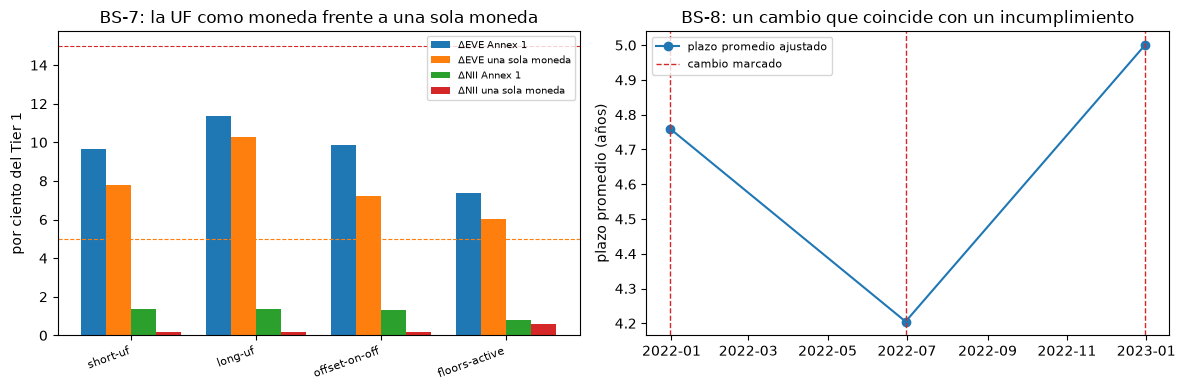

In [11]:
# Dibujar las medidas del Anexo 1 contra el contrafactual de una sola moneda, y el plazo ajustado con las fechas marcadas
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
names = list(compare)
x = np.arange(len(names))
left.bar(x - 0.3, [compare[v][0] * 100 for v in names], 0.2, label="ΔEVE Annex 1")
left.bar(x - 0.1, [compare[v][1] * 100 for v in names], 0.2, label="ΔEVE una sola moneda")
left.bar(x + 0.1, [compare[v][2] * 100 for v in names], 0.2, label="ΔNII Annex 1")
left.bar(x + 0.3, [compare[v][3] * 100 for v in names], 0.2, label="ΔNII una sola moneda")
left.axhline(15, color="tab:red", linestyle="--", linewidth=0.8)
left.axhline(5, color="tab:orange", linestyle="--", linewidth=0.8)
left.set_xticks(x)
left.set_xticklabels(names, rotation=20, ha="right", fontsize=8)
left.set_ylabel("por ciento del Tier 1")
left.set_title("BS-7: la UF como moneda frente a una sola moneda")
left.legend(fontsize=7)
run = rv_irrbb.behavioural_change_at_breach(np.array(wam), dates, breach)
right.plot(dates, wam, marker="o", color="tab:blue", label="plazo promedio ajustado")
for day in run.extras["flagged_dates"]:
    right.axvline(np.datetime64(day), color="tab:red", linestyle="--", linewidth=1)
right.axvline(dates[0], color="tab:red", linestyle="--", linewidth=1, label="cambio marcado")
right.set_ylabel("plazo promedio (años)")
right.set_title("BS-8: un cambio que coincide con un incumplimiento")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **BS-7, la separación.** Ninguna de las dos tablas de Basilea tiene el peso ni la UF (21 monedas cada una), y el motor rechaza un tamaño para ellos. La tabla chilena da al peso 300/400/200 pb y a la UR 200/250/150 pb para el EVE y 300 pb para el NII, y los documentos versionados llevan cada moneda en su propia curva: 4,50 por ciento en la primera banda para el peso y 1,21 por ciento para la UR. El piso tiene que ser el propio de la moneda: una caída de 200 pb lleva la curva UR a -0,795 por ciento en la primera banda, y el piso del peso de 0 por ciento actuaría en nueve bandas mientras el piso UR de -2 por ciento no actúa en ninguna.
- **BS-7, lo que pierde una sola moneda.** Tratar los flujos en UF como pesos (curva en pesos, tamaños del peso, piso en cero, sin cargo, una sola suma) da, para las variantes UF corto, UF largo y con y sin compensación, un delta NII de 1.356, 1.648 y 1.254 frente a los valores del Anexo 1 de 11.067, 11.213 y 11.016: de 6,8 a 8,8 veces menor. El delta EVE es 64.213, 84.710 y 59.422 frente a 79.643, 93.816 y 81.173: de 10 a 27 por ciento menor. En la variante con pisos activos, con una posición neta en UF de 5 por ciento del Tier 1, la diferencia es menor (4.653 frente a 6.606 en el NII). La razón al Tier 1 no cruza una línea en ninguno de los dos tratamientos en estas cuatro variantes, así que la afirmación no es que un banco pasaría o fallaría de otra manera, sino que la medida que define el regulador no es la que da un cálculo de una sola moneda.
- **BS-7, la compensación y el cargo.** La compensación baja el delta NII de 14.597 a 11.067 en la variante de UF corto (24 por ciento) y el delta EVE de 94.721 a 81.173 en la variante con y sin compensación (14 por ciento); en la variante de UF corto no cambia el delta EVE, porque el peor choque tiene ambos tramos perdiendo. El cargo es el 55,9, 55,1 y 56,1 por ciento del delta NII en las tres variantes con una posición neta en UF de 30 por ciento del Tier 1, y 15,6 por ciento en la de 5 por ciento.
- **BS-7, el límite.** Los pisos nunca actúan: la tasa posterior al choque más cercana está a 20,48 pb de su piso en las cuatro variantes, así que su efecto sobre un número no queda demostrado aquí. No hay una segunda implementación del Anexo 1 con la cual reconciliar; la búsqueda del dossier no encontró ninguna, lo que sigue sin verificarse más allá de ella. El banco es sintético, y la afirmación es regional.
- **BS-8, la discriminación.** En los cinco historiales construidos la prueba da el veredicto que dice la regla: verde para un parámetro mantenido fijo durante un incumplimiento, verde para un cambio sin incumplimiento, verde para un cambio antes del incumplimiento, roja para un cambio ante el incumplimiento (marcando el 2022-12-31), y no evaluada para una sola fecha.
- **BS-8, el banco versionado.** Con los parámetros versionados la proporción estable pedida (0,6) y el plazo estable pedido (5 años) no cambian y la prueba es verde; el plazo promedio ajustado se mueve, 4,7595, 4,2049 y 5,0 años, y la prueba es roja el 2022-06-30 y el 2022-12-31, las mismas fechas que los cambios versionados. Con las marcas de incumplimiento en falso, la misma serie es verde: la marca decide. Las filas versionadas son rojas al 2022-Q2 (un cambio) y al 2022-Q4 (dos), y no evaluada al 2021-Q4; la prueba con y sin conducta del EVE es roja en las tres fechas.
- **BS-8, el límite.** La prueba de valores atípicos se supera en las tres fechas, así que la marca nunca varía, y el parámetro que se mueve es uno ajustado que se reestima en cada fecha, por lo que difiere por construcción. El rojo no es entonces un hallazgo de que alguien ajustara el plazo para aliviar un incumplimiento; muestra que la prueba opera sobre esos parámetros y lo haría sobre un parámetro que un gerente cambiara. Lo que hace un validador con un rojo: preguntar quién movió el parámetro, cuándo y con qué aprobación; comparar el nuevo valor con los datos que lo respaldan (el cuaderno 05 muestra que los pesos ajustados no son estables entre ventanas); y leer el EVE con y sin conducta en la misma fecha. El comportamiento del banco es sintético.
- **Lo que el cuaderno no muestra.** Una reconciliación de las cifras chilenas con una segunda implementación, el efecto de un piso sobre un número, y un caso en que un gerente cambió un supuesto declarado ante un incumplimiento: los datos versionados no traen ninguno.

## Resumen

- BS-7: el Anexo chileno trata la UF como una moneda propia; el motor implementa sus tamaños, piso, compensación y cargo, y las variantes versionadas se recalculan desde él. Un tratamiento de una sola moneda con los mismos flujos daría un delta NII muy distinto, porque el cargo y el emparejamiento son lo que hace la medida de NII.
- BS-7 tiene límites: no hay una segunda implementación con la cual reconciliar, hay pisos que nunca actúan sobre estas curvas, un banco sintético y una afirmación regional.
- BS-8: la prueba de incumplimiento es roja cuando un parámetro cambia en una fecha con incumplimiento y verde en otro caso, y el veredicto lo decide la marca de incumplimiento.
- BS-8 tiene límites: en el banco versionado todas las fechas son un incumplimiento y el parámetro que se mueve es uno ajustado, así que el rojo muestra que la prueba opera, no que el banco hiciera lo que encontró la revisión del banco quebrado.
- Ambas afirmaciones se enuncian en el SDD solo hasta donde llega esta evidencia.

**Qué probar a continuación.** Cambia las marcas de incumplimiento de los historiales construidos y anota qué veredicto sigue a qué regla. Después lee las afirmaciones en la sección `## Beyond the state of the art` del SDD contra este cuaderno.

## Referencias

- CMF, Recopilación Actualizada de Normas, capítulo 21-13, Anexo 1 (la UR, los tamaños, los pisos, la compensación y el cargo). https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf
- BCBS, Standards: Interest rate risk in the banking book, SRP31.90 (los tamaños de choque) y SRP31.129. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2024), d578, Recalibration of shocks for interest rate risk in the banking book. https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf
- Board of Governors of the Federal Reserve System (2023), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- CMF, Informe del Desempeño del Sistema Bancario y Cooperativas, agosto de 2026. https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf
- FDIC, BankFind financials, dominio público. https://api.fdic.gov/banks/financials
- Departamento del Tesoro de EE. UU., Daily Treasury Par Yield Curve Rates, dominio público. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 03 (Chile, sección F.2) y dossier 05 (sección D.7) de la investigación de Contraste; la sección `## Beyond the state of the art` del SDD.